# 06 · Balance energético y sensibilidades

En [04](04_servicio_y_actividad.ipynb) he comprobado el servicio y su actividad; en [05](05_preparacion_y_ejecucion_copert.ipynb), los factores de consumo de COPERT. Ahora combino **personas, vehículos, recorridos y factores** para reproducir el balance anual de la ordenación recomendada. Comparo **2.500.000 visitas-persona en 2028 sin y con intervención**, conservando orígenes, calendario y restricciones.

**Recibe:** los productos aceptados de 01–05 de la misma ejecución y su configuración registrada. **Produce:** coeficientes por recorrido, consumos por programa y 16 productos anuales del balance y sus sensibilidades. **Comprueba:** conservación de visitas, cuentas por asignación y fecha, unidades, procedencia de factores y coherencia de los consumos y diferencias. Los resultados corresponden a la programación fijada; no busco otros horarios ni un óptimo nuevo.

El cálculo está en [etapas_registradas.py](../src/movilidad_teide/flujos/etapas_registradas.py), [preparacion_coeficientes.py](../src/movilidad_teide/energia/preparacion_coeficientes.py) y [balance_desde_perfiles.py](../src/movilidad_teide/flujos/balance_desde_perfiles.py). Las celdas llaman al código compartido y presentan sus cuentas. No generan ni modifican el informe o sus anexos.


## 1. Consultar resultados o calcular el balance de esta ejecución

Con **`consultar`**, opción inicial, leo 06 completada y preparo vistas de sus resultados. Con **`calcular`**, completo 06 desde 01–05 aceptadas en esa misma carpeta. Ambas acciones conservan la programación y las hipótesis del Excel. Una etapa aceptada no se sobrescribe: para repetirla inicio otra ejecución y completo sus dependencias.

06 utiliza las bibliotecas que 05 aceptó en ese registro y muestra su origen. Consultar factores distribuidos, calcular el balance y derivar vistas no lanzan por sí solos el motor COPERT.

La sección 9 contiene una vista física adicional. Su celda la deriva en memoria desde los productos de 06, también al consultar, sin leer anexos Gold ni modificar la etapa aceptada. Esta operación se identifica expresamente; ninguna referencia suple una entrada de cálculo ausente.


In [1]:
from pathlib import Path
import sys,json,hashlib
import pandas as pd
import numpy as np
from IPython.display import display,Markdown
candidatas = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
RAIZ = next((p for p in candidatas if (p / "pyproject.toml").is_file()
             and (p / "config/parametros_modelo.xlsx").is_file()), None)
if RAIZ is None:
    raise FileNotFoundError("Abra este cuaderno desde la raíz del proyecto o desde notebooks/.")
sys.path.insert(0,str(RAIZ / "src"))
from movilidad_teide.configuracion.registro import abrir_ejecucion
from movilidad_teide.flujos.etapas_registradas import ejecutar_etapa
from movilidad_teide.informe.temporal import datos_temporales,envolvente_temporal
from movilidad_teide.informe.sensibilidad_actual import calcular_sensibilidad_fisica


In [2]:
ACCION_BALANCE = "consultar"  # Alternativa explícita: "calcular".
RUTA_EJECUCION = Path("data/silver/ejecuciones/referencia_2028_final_20261116")


In [3]:
if ACCION_BALANCE not in {"consultar","calcular"}:
    raise ValueError('ACCION_BALANCE debe ser "consultar" o "calcular".')
EJECUCION = RAIZ / RUTA_EJECUCION
if not (EJECUCION / "registro_ejecucion.json").is_file():
    raise FileNotFoundError("No existe el registro. Inicie 00 y prepare 01–05 indicando la misma ruta.")
DATOS = abrir_ejecucion(RAIZ,EJECUCION)
if ACCION_BALANCE == "calcular":
    faltan = [s for s in ["01","02","03","04","05"] if DATOS["estado_etapas"]["etapas"][s]["estado"] != "completada"]
    if faltan:
        raise ValueError("Complete primero las etapas de esta ejecución: "+", ".join(faltan))
    if DATOS["estado_etapas"]["etapas"]["06"]["estado"] == "completada":
        raise ValueError("06 ya está completada. Inicie otra ejecución para repetir su cálculo.")
    ejecutar_etapa(RAIZ,EJECUCION,"06",accion="calcular")
    DATOS = abrir_ejecucion(RAIZ,EJECUCION)
ETAPA = DATOS["estado_etapas"]["etapas"]["06"]
if ETAPA["estado"] != "completada":
    raise ValueError("06 no está completada. Prepare 01–05 y elija calcular en esta ejecución.")
RESULTADOS = EJECUCION / ETAPA["carpeta"]
PREPARACION = RESULTADOS / "calculo"
CFG = DATOS["configuracion"]["valores"]
META = json.loads((RESULTADOS / "metadatos.json").read_text())
def leer(nombre):
    return pd.read_csv(RESULTADOS / "balance" / nombre,sep=";",float_precision="round_trip")
RECOMENDACION = json.loads((RESULTADOS / "balance/recomendacion.json").read_text())
POLITICA = RECOMENDACION["politica_recomendada"]
ANUAL_TODO = leer("balance_anual_politicas.csv")
ANUAL = ANUAL_TODO.loc[ANUAL_TODO.politica.eq(POLITICA)].copy()
PRINCIPAL = ANUAL.loc[ANUAL.tratamiento.eq("Hot COPERT") & ANUAL.km_posicionamiento_unidad_activacion.eq(CFG["posicionamiento_km"])].copy()
CONTRASTE = ANUAL.loc[ANUAL.tratamiento.eq("Contraste FTA lanzaderas y posicionamiento") & ANUAL.km_posicionamiento_unidad_activacion.eq(CFG["posicionamiento_km"])].copy()
CALENDARIO = leer("recomendada_calendario.csv")
DIARIO = leer("actividad_y_energia_diaria_politicas.csv")
DIARIO = DIARIO.loc[DIARIO.politica.eq(POLITICA)].copy()
SENSIBILIDAD = leer("sensibilidad_excursiones/balance_anual.csv")
ASIGNACIONES = sorted(PRINCIPAL.asignacion_turismos.unique())
assert len(PRINCIPAL)==len(CONTRASTE)==2
assert META["visitas_sin_y_con"]==CFG["visitas_anio"] and not META["lecturas_gold_durante_calculo"]
print("Acción realizada:",ACCION_BALANCE)
print("Ejecución:",DATOS["registro"]["identificador"])
print("Carpeta de resultados dentro de la ejecución:",ETAPA["carpeta"])
print("Procedencia:",META["procedencia"])
print("Origen de los factores de05:",DATOS["estado_etapas"]["etapas"]["05"]["accion"])
print("Motor COPERT nuevo durante 06: no; los factores proceden de05.")
def mostrar(tabla,titulo,formatos=None):
    display(tabla.style.set_uuid("balance06").hide(axis="index").set_caption(titulo)
            .format(formatos or {},decimal=",",thousands=" ",na_rep="No cuantificado / no procede"))
def etiqueta(asignacion):
    return "España no Tenerife: alquiler" if asignacion.endswith("alquiler") else "España no Tenerife: coche particular"
def banda(lo,hi,dec=2):
    return (f"{lo:,.{dec}f}"+"–"+f"{hi:,.{dec}f}").replace(","," ").replace(".",",")


Acción realizada: consultar
Ejecución: referencia_2028_paquetes_20261116
Carpeta de resultados dentro de la ejecución: resultados/06/523b20eb58e44554ab7808d3358b08ed
Procedencia: Productos conectados01–05; sin recalcular demanda/geografía ni releer sus referencias anteriores
Origen de los factores de05: consultar
Motor COPERT nuevo durante 06: no; los factores proceden de05.


## 2. De los datos al consumo y al ahorro

**Tabla 1. Entradas y transformaciones del balance del Teide, referencia 2028.** Todas las preparaciones se localizan mediante el mismo registro; los resultados nuevos se guardan en Silver o en su destino externo identificado. Las referencias Gold sirven para la comparación posterior, no para producir los coeficientes.

| Entrada aceptada | Uso en 06 | Resultado |
|---|---|---|
| 01 · Demanda por origen, modo y fecha | Conservar las mismas personas y convertirlas en actividad conforme a las cargas elegidas | Visitas y vehículos equivalentes por fecha |
| 02 · Recorridos, segmentos, pendientes y clases de vía | Aplicar distancias y perfiles dirigidos, incluidos los accesos reasignados | Actividad y energía por recorrido |
| 03 · Selección técnica del parque | Ponderar categorías y tecnologías con la representación fijada | Factores y masas por grupo de turismos |
| 04 · Programas físicos comprobados | Valorar sus circulaciones comerciales, vacíos, coches y regreso | Consumos por programa, sin crear más servicios |
| 05 · Bibliotecas COPERT aceptadas | Aplicar factores de energía por kilómetro y condiciones técnicas | Coeficientes nuevos, nunca una biblioteca alternativa no registrada |
| Excel y decisiones técnicas registradas | Mantener ocupaciones, ajustes, sustitución, posicionamiento y conversiones | Cuentas anuales y sensibilidades comparables |

Los **turismos** usan las velocidades energéticas de 20/40/80 km/h. La pendiente se ajusta fuera de COPERT para gasolina y diésel convencionales, con las masas y rendimientos del estudio; las demás tecnologías mantienen su consumo base. **TITSA 342/348 y lanzaderas** utilizan perfiles dirigidos y factores de autocar a 34 km/h, con carga técnica 0,5 en comercial y 0 en vacío. Los tiempos del servicio no se sustituyen por dividir sus kilómetros entre esas velocidades.

Las **excursiones** parten de los orígenes representativos de la demanda e incluyen acceso, interior próximo y regreso, con 35,99 personas por autocar y el factor de pendiente cero. Su actividad se conserva en el principal; por eso su consumo calculado es igual sin/con y se cancela en la diferencia. Su simplificación de pendiente sí afecta al consumo absoluto y a la sensibilidad de crecimiento.

Los **coches autorizados realizan también el interior en coche en ambos escenarios modelizados**. Los viajeros de lanzadera llegan en coche a la cabecera asignada, incluidos los antiguos viajeros de las líneas de acceso de TITSA, el operador Transportes Interurbanos de Tenerife. Ese gasto sí se cuenta; no convierte un transbordo en otra visita. Las reasignaciones retiran el consumo del acceso anterior y añaden el del acceso efectivamente elegido.


## 3. Qué significan los resultados y sus intervalos

**Consumo identificado** es la energía de las partidas que se han cuantificado. Incluye los coches directos y su interior, los accesos privados a cabeceras, las excursiones, las líneas de acceso TITSA sin proyecto, las lanzaderas comerciales, sus movimientos en vacío y el posicionamiento de sustitutas externas. Este último adopta 100 km totales de llegada y retirada por unidad disponible y activación, sin programarles expediciones comerciales nuevas.

La línea 341 y otros servicios interiores u oficiales se suponen iguales sin/con, pero su consumo absoluto todavía no está cuantificado. Tampoco se incluyen instalaciones fijas ni el incremento de arranque en frío. **Ausencia de dato no significa consumo cero.** Bajo la igualdad de las partidas comunes se cancelan en la resta; si cambian, su diferencia modifica el ahorro. Por eso aquí no presento un porcentaje sobre el consumo absoluto completo.

Se conservan dos **asignaciones de turismos**: las personas de España no Tenerife se representan en coche de alquiler o particular. En ambas, residentes de Tenerife usan particular y extranjeros, alquiler. No sumo las dos asignaciones: son cuentas alternativas de las mismas visitas.

La banda añade los extremos técnicos de accesos cuya clase de carretera no está resuelta. **No es un intervalo estadístico ni una probabilidad.** Resto consumo sin menos consumo con dentro de cada asignación y solo después formo la envolvente. No resto el menor «sin» de una asignación y el mayor «con» de otra.

Unidades: **MWh**, megavatio hora; **kWh**, kilovatio hora; **tep**, tonelada equivalente de petróleo. El estudio utiliza 1 tep = 11,63 MWh y 1 MWh = 1.000 kWh. Los ratios anuales se dividen entre 2.500.000 visitas; los de cada régimen usan sus visitas, sin promediar ratios diarios con el mismo peso.


## 4. Resultado anual de la ordenación recomendada

**Tabla 2. Consumo y ahorro identificados por asignación de turismos, Teide 2028.** Fuente: `balance_anual_politicas.csv` de 06, selección recomendada, motor caliente de COPERT y 100 km por apoyo disponible y activación. Cada fila representa 2.500.000 visitas; las filas no se suman. Las bandas corresponden a accesos de clase no resuelta, no a confianza estadística. Los consumos comunes sin cuantificar quedan fuera.


In [4]:
filas=[]
for r in PRINCIPAL.itertuples():
    np.testing.assert_allclose([r.sin_identificado_mwh-r.con_identificado_max_mwh,r.sin_identificado_mwh-r.con_identificado_min_mwh],
                              [r.ahorro_min_mwh,r.ahorro_max_mwh],rtol=0,atol=1e-8)
    filas.append({"Coches de España no Tenerife":etiqueta(r.asignacion_turismos),
        "Sin: MWh/año":r.sin_identificado_mwh,"Con: MWh/año":banda(r.con_identificado_min_mwh,r.con_identificado_max_mwh),
        "Ahorro: MWh/año":banda(r.ahorro_min_mwh,r.ahorro_max_mwh),
        "Sin: tep/año":r.sin_identificado_mwh/CFG["mwh_por_tep"],
        "Con: tep/año":banda(r.con_identificado_min_mwh/CFG["mwh_por_tep"],r.con_identificado_max_mwh/CFG["mwh_por_tep"]),
        "Ahorro: tep/año":banda(r.ahorro_min_tep,r.ahorro_max_tep)})
mostrar(pd.DataFrame(filas),"Tabla 2 · Balance identificado anual por asignación · Teide 2028 · 2.500.000 visitas, COPERT en caliente",{"Sin: MWh/año":"{:,.2f}","Sin: tep/año":"{:,.2f}"})
por_visita=[]
for r in PRINCIPAL.itertuples():
    por_visita.append({"Coches de España no Tenerife":etiqueta(r.asignacion_turismos),
       "Sin: kWh/visita":1000*r.sin_identificado_mwh/CFG["visitas_anio"],
       "Con: kWh/visita":banda(r.con_min_kwh_visita,r.con_max_kwh_visita,3),
       "Ahorro: kWh/visita":banda(r.ahorro_min_kwh_visita,r.ahorro_max_kwh_visita,3),
       "Con: tep/visita":banda(r.con_identificado_min_mwh/CFG["mwh_por_tep"]/CFG["visitas_anio"],r.con_identificado_max_mwh/CFG["mwh_por_tep"]/CFG["visitas_anio"],7),
       "Ahorro: tep/visita":banda(r.ahorro_min_tep/CFG["visitas_anio"],r.ahorro_max_tep/CFG["visitas_anio"],7)})
mostrar(pd.DataFrame(por_visita),"Tabla 3 · Consumo y ahorro identificados por visita · Teide 2028 · Denominador:2.500.000 visitas/año",{"Sin: kWh/visita":"{:,.3f}"})
assert PRINCIPAL.consumo_comun_absoluto_mwh.isna().all() and PRINCIPAL.porcentaje_global_ahorro.isna().all()


Coches de España no Tenerife,Sin: MWh/año,Con: MWh/año,Ahorro: MWh/año,Sin: tep/año,Con: tep/año,Ahorro: tep/año
España no Tenerife: alquiler,"39 162,48","34 427,96–34 474,52","4 687,96–4 734,51","3 367,37","2 960,27–2 964,27","403,09–407,09"
España no Tenerife: coche particular,"39 329,57","34 542,26–34 587,33","4 742,24–4 787,31","3 381,73","2 970,10–2 973,97","407,76–411,63"


Coches de España no Tenerife,Sin: kWh/visita,Con: kWh/visita,Ahorro: kWh/visita,Con: tep/visita,Ahorro: tep/visita
España no Tenerife: alquiler,"15,665","13,771–13,790","1,875–1,894","0,0011841–0,0011857","0,0001612–0,0001628"
España no Tenerife: coche particular,"15,732","13,817–13,835","1,897–1,915","0,0011880–0,0011896","0,0001631–0,0001647"


## 5. Qué gasto aporta cada modo y cómo se evita el doble conteo

La tabla 4 agrupa únicamente las columnas de energía ya calculadas de las 366 fechas, dentro de cada asignación. Es una vista contable de los resultados; no obtiene otros factores ni recalcula recorridos. En el coche a cabeceras se resta el acceso que se sustituye y se añade el nuevo. La alimentación de anteriores viajeros TITSA se separa para hacer visible esa hipótesis. Los movimientos en vacío sí consumen, aunque no ofrecen plazas comerciales.

**Tabla 4. Ocho componentes de energía identificada por modo y función, Teide 2028, MWh/año.** Fuente: cuentas diarias calculadas de 06. Motor caliente,100 km por apoyo y activación. Cada asignación conserva su cuenta completa; las bandas de filas o asignaciones no se suman por sus extremos para obtener otro ahorro.


In [5]:
# Agregación de columnas contables ya valoradas por el productor común.
componentes=[]
for alt,g in DIARIO.groupby("asignacion_turismos",sort=False):
    r=PRINCIPAL.set_index("asignacion_turismos").loc[alt]
    pares=[("Coches directos e interior","sin_coche_mwh_dia","con_coche_mwh_dia"),
           ("Excursiones","sin_excursion_mwh_dia","con_excursion_mwh_dia"),
           ("TITSA de acceso","sin_TITSA_mwh_dia",None),
           ("Coche a cabeceras",None,None),
           ("Coche de anteriores viajeros TITSA",None,"con_alimentador_TITSA_mwh_dia"),
           ("Lanzaderas comerciales",None,"con_lanzadera_comercial_mwh_dia"),
           ("Lanzaderas en vacío",None,"con_lanzadera_vacia_mwh_dia"),
           ("Posicionamiento de externas",None,None)]
    for nombre,antes,despues in pares:
        sin=float(g[antes].sum()) if antes else 0.
        lo=hi=float(g[despues].sum()) if despues else 0.
        if nombre=="Coche a cabeceras":
            comun=g.con_alimentador_habitual_mwh_dia-g.alimentador_antiguo_retirado_mwh_dia+g.con_alimentador_otro_colectivo_mwh_dia
            lo=float((comun+g.alimentador_nuevo_min_mwh_dia).sum())
            hi=float((comun+g.alimentador_nuevo_max_mwh_dia).sum())
        if nombre=="Posicionamiento de externas":lo=hi=float(r.posicionamiento_mwh)
        componentes.append(dict(asignacion=alt,componente=nombre,sin_mwh=sin,con_min_mwh=lo,con_max_mwh=hi))
COMPONENTES=pd.DataFrame(componentes)
for alt,g in COMPONENTES.groupby("asignacion"):
    r=PRINCIPAL.set_index("asignacion_turismos").loc[alt]
    np.testing.assert_allclose(g[["sin_mwh","con_min_mwh","con_max_mwh"]].sum(),[r.sin_identificado_mwh,r.con_identificado_min_mwh,r.con_identificado_max_mwh],rtol=0,atol=1e-8)
tabla=COMPONENTES.assign(Asignación=COMPONENTES.asignacion.map(etiqueta),**{"Con (MWh/año)":[banda(a,b) for a,b in zip(COMPONENTES.con_min_mwh,COMPONENTES.con_max_mwh)]})
mostrar(tabla[["Asignación","componente","sin_mwh","Con (MWh/año)"]].rename(columns={"componente":"Componente","sin_mwh":"Sin (MWh/año)"}),"Tabla 4 · Componentes de energía identificada · Teide 2028,366fechas · Fuente: cuentas diarias de 06",{"Sin (MWh/año)":"{:,.2f}"})


Asignación,Componente,Sin (MWh/año),Con (MWh/año)
España no Tenerife: alquiler,Coches directos e interior,"34 180,98","13 823,49–13 823,49"
España no Tenerife: alquiler,Excursiones,"4 678,26","4 678,26–4 678,26"
España no Tenerife: alquiler,TITSA de acceso,"303,24","0,00–0,00"
España no Tenerife: alquiler,Coche a cabeceras,"0,00","7 892,15–7 938,70"
España no Tenerife: alquiler,Coche de anteriores viajeros TITSA,"0,00","102,57–102,57"
España no Tenerife: alquiler,Lanzaderas comerciales,"0,00","5 701,55–5 701,55"
España no Tenerife: alquiler,Lanzaderas en vacío,"0,00","2 221,43–2 221,43"
España no Tenerife: alquiler,Posicionamiento de externas,"0,00","8,51–8,51"
España no Tenerife: coche particular,Coches directos e interior,"34 348,07","13 890,20–13 890,20"
España no Tenerife: coche particular,Excursiones,"4 678,26","4 678,26–4 678,26"


## 6. Jornadas ordinarias, puntas y distribución temporal

Una punta **sustituye** a la operación ordinaria de esa fecha; no se añade como otro día. El calendario adoptado utiliza 266 fechas ordinarias y 100 de punta, con 20/23/24/27 propias en ordinaria y 28/30 en punta. Veintisiete sigue siendo un máximo, no una flota fija diaria. Las externas se mantienen para sustitución; su posicionamiento se contabiliza cuando están disponibles, aunque no hagan servicios comerciales.

El módulo común [datos_temporales](../src/movilidad_teide/informe/temporal.py) reconstruye las cuentas de presentación, incorpora ese posicionamiento y las concilia con cada asignación anual. No modifica los productos de 06 ni genera anexos. La tabla 5 muestra sumas de todas las fechas de cada régimen y ratios ponderados por sus visitas. La figura 1 sitúa su energía y las seis flotas en el año de planificación; las bandas reúnen asignaciones y extremos técnicos, no probabilidades.

**Tabla 5. Visitas, actividad y energía identificada por régimen y año, Teide 2028.** Fuente: productos diarios y calendario de 06; MWh y tep son sumas del periodo, y kWh/visita utiliza sus visitas. Motor caliente,100 km por apoyo/activación. Las asignaciones alternativas no se suman.


In [6]:
DATOS_VISTAS={"referencia":DATOS["configuracion"],"tablas":{"calendario_operativo":CALENDARIO,"actividad_diaria":DIARIO,"central":PRINCIPAL}}
TEMPORAL=datos_temporales(DATOS_VISTAS)
BANDA_TEMPORAL=envolvente_temporal(TEMPORAL)
metricas=["sin_mwh_dia","con_min_mwh_dia","con_max_mwh_dia","ahorro_min_mwh_dia","ahorro_max_mwh_dia"]
CUENTAS=TEMPORAL.groupby(["regimen","asignacion_turismos"],sort=False)[["visitas_sin_dia",*metricas]].sum().reset_index()
CUENTAS["dias"]=[int(CALENDARIO.regimen.eq(r).sum()) for r in CUENTAS.regimen]
for alt,g in TEMPORAL.groupby("asignacion_turismos",sort=False):
    fila={"regimen":"Total anual","asignacion_turismos":alt,"dias":len(CALENDARIO)}
    fila.update(g[["visitas_sin_dia",*metricas]].sum().to_dict());CUENTAS=pd.concat([CUENTAS,pd.DataFrame([fila])],ignore_index=True)
filas=[]
for r in CUENTAS.itertuples():
    filas.append({"Régimen":r.regimen,"Asignación":etiqueta(r.asignacion_turismos),"Días":r.dias,"Visitas":r.visitas_sin_dia,
     "Sin: MWh":r.sin_mwh_dia,"Con: MWh":banda(r.con_min_mwh_dia,r.con_max_mwh_dia),"Ahorro: MWh":banda(r.ahorro_min_mwh_dia,r.ahorro_max_mwh_dia),
     "Con: tep":banda(r.con_min_mwh_dia/CFG["mwh_por_tep"],r.con_max_mwh_dia/CFG["mwh_por_tep"]),
     "Ahorro: tep":banda(r.ahorro_min_mwh_dia/CFG["mwh_por_tep"],r.ahorro_max_mwh_dia/CFG["mwh_por_tep"]),
     "Con: kWh/visita":banda(1000*r.con_min_mwh_dia/r.visitas_sin_dia,1000*r.con_max_mwh_dia/r.visitas_sin_dia,3),
     "Ahorro: kWh/visita":banda(1000*r.ahorro_min_mwh_dia/r.visitas_sin_dia,1000*r.ahorro_max_mwh_dia/r.visitas_sin_dia,3)})
mostrar(pd.DataFrame(filas),"Tabla 5 · Energía identificada de ordinarias, puntas y año completo · Teide 2028 · Cada fecha se cuenta una vez",{"Visitas":"{:,.0f}","Sin: MWh":"{:,.2f}"})
np.testing.assert_allclose(CALENDARIO.visitas_sin_dia.sum(),CFG["visitas_anio"],rtol=0,atol=1e-8)
np.testing.assert_allclose(CALENDARIO[["visitas_coche_dia","visitas_excursion_dia","visitas_lanzadera_dia"]].sum().sum(),CFG["visitas_anio"],rtol=0,atol=1e-8)


Régimen,Asignación,Días,Visitas,Sin: MWh,Con: MWh,Ahorro: MWh,Con: tep,Ahorro: tep,Con: kWh/visita,Ahorro: kWh/visita
Ordinaria,España no Tenerife: alquiler,266,1 738 981,"27 198,89","23 950,16–23 951,45","3 247,45–3 248,73","2 059,34–2 059,45","279,23–279,34","13,773–13,773","1,867–1,868"
Ordinaria,España no Tenerife: coche particular,266,1 738 981,"27 317,21","24 031,36–24 032,61","3 284,61–3 285,85","2 066,33–2 066,43","282,43–282,53","13,819–13,820","1,889–1,890"
Punta,España no Tenerife: alquiler,100,761 019,"11 963,59","10 477,80–10 523,07","1 440,51–1 485,78","900,93–904,82","123,86–127,75","13,768–13,828","1,893–1,952"
Punta,España no Tenerife: coche particular,100,761 019,"12 012,35","10 510,89–10 554,72","1 457,63–1 501,46","903,77–907,54","125,33–129,10","13,812–13,869","1,915–1,973"
Total anual,España no Tenerife: alquiler,366,2 500 000,"39 162,48","34 427,96–34 474,52","4 687,96–4 734,51","2 960,27–2 964,27","403,09–407,09","13,771–13,790","1,875–1,894"
Total anual,España no Tenerife: coche particular,366,2 500 000,"39 329,57","34 542,26–34 587,33","4 742,24–4 787,31","2 970,10–2 973,97","407,76–411,63","13,817–13,835","1,897–1,915"


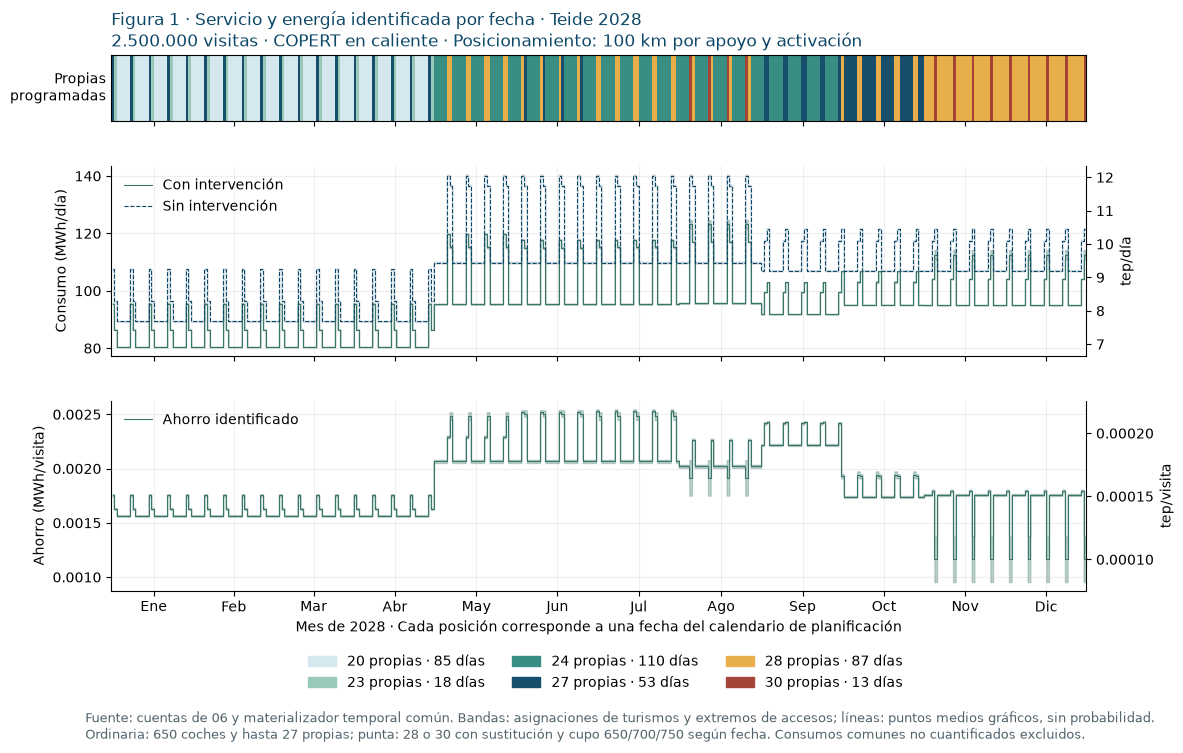

In [7]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.colors import ListedColormap,BoundaryNorm
fechas=pd.to_datetime(BANDA_TEMPORAL.fecha)
colores={20:"#d5e7ef",23:"#99c9b9",24:"#398e83",27:"#174e6b",28:"#e7ae49",30:"#a44437"}
fig,axes=plt.subplots(3,1,figsize=(13,8),sharex=True,gridspec_kw={"height_ratios":[.35,1,1]})
niveles=list(colores);indices=np.array([niveles.index(int(v)) for v in BANDA_TEMPORAL.programadas])
import matplotlib.dates as mdates
x=mdates.date2num(fechas)
axes[0].pcolormesh(np.r_[x-.5,x[-1]+.5],[0,1],indices[None,:],cmap=ListedColormap(list(colores.values())),norm=BoundaryNorm(np.arange(-.5,6.5),6))
axes[0].set_yticks([]);axes[0].set_ylabel("Propias\nprogramadas",rotation=0,ha="right",va="center")
axes[0].set_title("Figura 1 · Servicio y energía identificada por fecha · Teide 2028\n2.500.000 visitas · COPERT en caliente · Posicionamiento: 100 km por apoyo y activación",loc="left",color="#0C4767")
for ax,tipo,unidad in [(axes[1],"con","mwh_dia"),(axes[2],"ahorro","mwh_visita")]:
    lo=BANDA_TEMPORAL[tipo+"_min_"+unidad].to_numpy();hi=BANDA_TEMPORAL[tipo+"_max_"+unidad].to_numpy()
    ax.fill_between(x,lo,hi,step="mid",alpha=.3,color="#397568")
    ax.step(x,(lo+hi)/2,where="mid",lw=.8,color="#397568",label="Con intervención" if tipo=="con" else "Ahorro identificado")
    if tipo=="con":
        a=BANDA_TEMPORAL["sin_min_"+unidad].to_numpy();b=BANDA_TEMPORAL["sin_max_"+unidad].to_numpy()
        ax.fill_between(x,a,b,step="mid",alpha=.15,color="#0C4767");ax.step(x,(a+b)/2,where="mid",lw=.8,color="#0C4767",ls="--",label="Sin intervención")
    ax.set_ylabel("Consumo (MWh/día)" if tipo=="con" else "Ahorro (MWh/visita)")
    derecho=ax.secondary_yaxis("right",functions=(lambda v:v/CFG["mwh_por_tep"],lambda v:v*CFG["mwh_por_tep"]))
    derecho.set_ylabel("tep/día" if tipo=="con" else "tep/visita")
    ax.grid(alpha=.2);ax.legend(frameon=False,loc="upper left");ax.spines[["top","right"]].set_visible(False)
limites=mdates.date2num(pd.date_range("2028-01-01","2029-01-01",freq="MS"))
centros=(limites[:-1]+limites[1:])/2
axes[-1].set_xticks(centros,labels=["Ene","Feb","Mar","Abr","May","Jun","Jul","Ago","Sep","Oct","Nov","Dic"])
axes[-1].set_xlim(x[0]-.5,x[-1]+.5)
axes[-1].set_xlabel("Mes de 2028 · Cada posición corresponde a una fecha del calendario de planificación")
fig.legend(handles=[Patch(color=c,label=f"{n} propias · {int(CALENDARIO.programadas.eq(n).sum())} días") for n,c in colores.items()],loc="lower center",bbox_to_anchor=(.5,.06),ncol=3,frameon=False)
fig.text(.1,.015,"Fuente: cuentas de 06 y materializador temporal común. Bandas: asignaciones de turismos y extremos de accesos; líneas: puntos medios gráficos, sin probabilidad.\nOrdinaria: 650 coches y hasta 27 propias; punta: 28 o 30 con sustitución y cupo 650/700/750 según fecha. Consumos comunes no cuantificados excluidos.",fontsize=9,color="#53636C")
fig.subplots_adjust(left=.12,right=.87,top=.87,bottom=.2,hspace=.3)
plt.show()


## 7. Sensibilidades de explotación y posicionamiento

El principal utiliza factores de **motor caliente**, denominados Hot en COPERT. Como contraste se conserva la hipótesis de la Federal Transit Administration (FTA): una pérdida de rendimiento de 10%en lanzaderas y posicionamiento. A igual distancia supone dividir ese bloque energético por 0,90, es decir,11,111%más energía; no incrementar 10%todo el consumo del Parque. Es una sensibilidad externa, no una medición local ni una corrección nativa de COPERT.

La distancia de posicionamiento contrasta 0,50 y 100 km totales por unidad externa disponible y activación, con el mismo servicio comercial. Cero elimina únicamente ese gasto en la sensibilidad, no la necesidad de las sustitutas. La tabla 6 toma directamente los resultados anuales calculados para cada tratamiento y distancia, manteniendo la cuenta completa de cada asignación.

**Tabla 6. Consumo y ahorro identificados al variar explotación y posicionamiento, Teide 2028.** Fuente: resultados anuales de 06 para la política recomendada. Cada caso conserva 2.500.000 visitas, las circulaciones seleccionadas y sus restricciones. La banda reúne asignaciones y extremos técnicos; no se suman casos.


In [8]:
filas=[]
for (tratamiento,km),g in ANUAL.groupby(["tratamiento","km_posicionamiento_unidad_activacion"],sort=False):
    filas.append({"Tratamiento":"Motor caliente" if tratamiento=="Hot COPERT" else "Contraste FTA: pérdida de rendimiento 10%",
      "Posicionamiento: km/unidad y activación":km,
      "Con: MWh/año":banda(g.con_identificado_min_mwh.min(),g.con_identificado_max_mwh.max()),
      "Ahorro: MWh/año":banda(g.ahorro_min_mwh.min(),g.ahorro_max_mwh.max()),
      "Con: tep/año":banda(g.con_identificado_min_mwh.min()/CFG["mwh_por_tep"],g.con_identificado_max_mwh.max()/CFG["mwh_por_tep"]),
      "Ahorro: tep/año":banda(g.ahorro_min_tep.min(),g.ahorro_max_tep.max()),
      "Con: kWh/visita":banda(g.con_min_kwh_visita.min(),g.con_max_kwh_visita.max(),3),
      "Ahorro: kWh/visita":banda(g.ahorro_min_kwh_visita.min(),g.ahorro_max_kwh_visita.max(),3)})
mostrar(pd.DataFrame(filas),"Tabla 6 · Sensibilidad de explotación y posicionamiento · Teide 2028 · Mismas2.500.000 visitas y servicio")


Tratamiento,Posicionamiento: km/unidad y activación,Con: MWh/año,Ahorro: MWh/año,Con: tep/año,Ahorro: tep/año,Con: kWh/visita,Ahorro: kWh/visita
Motor caliente,0,"34 419,45–34 578,81","4 696,47–4 795,82","2 959,54–2 973,24","403,82–412,37","13,768–13,832","1,879–1,918"
Contraste FTA: pérdida de rendimiento 10%,0,"35 299,78–35 459,14","3 816,14–3 915,49","3 035,24–3 048,94","328,13–336,67","14,120–14,184","1,526–1,566"
Motor caliente,50,"34 423,71–34 583,07","4 692,22–4 791,56","2 959,91–2 973,61","403,46–412,00","13,769–13,833","1,877–1,917"
Contraste FTA: pérdida de rendimiento 10%,50,"35 304,51–35 463,87","3 811,41–3 910,76","3 035,64–3 049,34","327,72–336,26","14,122–14,186","1,525–1,564"
Motor caliente,100,"34 427,96–34 587,33","4 687,96–4 787,31","2 960,27–2 973,97","403,09–411,63","13,771–13,835","1,875–1,915"
Contraste FTA: pérdida de rendimiento 10%,100,"35 309,24–35 468,60","3 806,68–3 906,03","3 036,05–3 049,75","327,32–335,86","14,124–14,187","1,523–1,562"


## 8. Más excursiones con las mismas visitas

Un aumento de **10% o 25%** multiplica por 1,10 o 1,25 las visitas de excursión del escenario sin intervención en las mismas fechas. No es una cuota del total, más visitantes ni ese porcentaje de autobuses físicos. Esas personas pasan de la demanda de lanzadera a excursión; el total sigue siendo 2.500.000 y se mantiene el cupo de coches.

Con **servicio sin reducir** se conservan las expediciones principales de lanzadera. Con **servicio ajustado** se seleccionan circulaciones comprobadas para la demanda restante, respetando plazas, vehículos, sustitución y regresos. Mantener la oferta cuando bajan sus pasajeros puede reducir la ocupación y no necesariamente mejorar el ahorro; no se presupone el resultado.

La tabla 7 muestra visitas, servicios y ocupación; la tabla 8, consumo y ahorro identificados. Se mantiene la hipótesis de 35,99 personas por autocar equivalente. Su capacidad nominal efectiva no está identificada: no se atribuye un porcentaje real de llenado. Los servicios de excursión son equivalentes de ida y regreso, no una flota identificada. La ocupación de lanzaderas usa dos embarques por visita sobre 46 plazas comerciales por expedición.

**Tabla 7. Actividad y ocupación de la sensibilidad de excursiones, Teide 2028.** Fuente: resultados anuales de 06. Cada alternativa conserva 2.500.000 visitas; no se acumula con el principal. El aumento se refiere a visitas de excursión sin intervención, no a autobuses físicos.


In [9]:
SENS_HOT=SENSIBILIDAD.loc[SENSIBILIDAD.tratamiento.eq("Hot COPERT")].copy()
filas=[];energias=[]
for (inc,oferta),g in SENS_HOT.groupby(["incremento_excursiones","oferta"],sort=False):
    r=g.iloc[0];nombre="Sin reducir" if oferta=="Oferta conservada" else "Ajustado a demanda"
    np.testing.assert_allclose(g[["visitas_coche","visitas_excursion","visitas_lanzadera"]].sum(axis=1),CFG["visitas_anio"],rtol=0,atol=1e-8)
    filas.append({"Aumento de visitas de excursión":f"+{inc:.0%}","Servicio de lanzadera":nombre,"Visitas en coche":r.visitas_coche,
      "Visitas en excursión":r.visitas_excursion,"Visitas en lanzadera":r.visitas_lanzadera,
      "Excursiones equivalentes (ida y regreso)":r.visitas_excursion/CFG["ocupacion_guagua_aforo"],
      "Expediciones de lanzadera (un sentido)":r.expediciones,"Ocupación de46 plazas comerciales (%)":r.ocupacion_diseno_pct})
    energias.append({"Aumento de visitas de excursión":f"+{inc:.0%}","Servicio de lanzadera":nombre,
      "Con: MWh/año":banda(g.con_min_mwh.min(),g.con_max_mwh.max()),"Ahorro: MWh/año":banda(g.ahorro_min_mwh.min(),g.ahorro_max_mwh.max()),
      "Con: tep/año":banda(g.con_min_mwh.min()/CFG["mwh_por_tep"],g.con_max_mwh.max()/CFG["mwh_por_tep"]),
      "Ahorro: tep/año":banda(g.ahorro_min_tep.min(),g.ahorro_max_tep.max()),
      "Con: kWh/visita":banda(g.con_min_kwh_visita.min(),g.con_max_kwh_visita.max(),3),"Ahorro: kWh/visita":banda(g.ahorro_min_kwh_visita.min(),g.ahorro_max_kwh_visita.max(),3)})
actividades=pd.DataFrame(filas)
mostrar(actividades,"Tabla 7 · Sensibilidad de excursiones: visitas, servicios y ocupación · Teide 2028",{k:"{:,.1f}" for k in actividades.columns if k not in ["Aumento de visitas de excursión","Servicio de lanzadera"]})
mostrar(pd.DataFrame(energias),"Tabla 8 · Energía identificada en la sensibilidad de excursiones · Teide 2028 · Motor caliente,100 km por apoyo/activación")


Aumento de visitas de excursión,Servicio de lanzadera,Visitas en coche,Visitas en excursión,Visitas en lanzadera,Excursiones equivalentes (ida y regreso),Expediciones de lanzadera (un sentido),Ocupación de46 plazas comerciales (%)
+10%,Sin reducir,"771 840,0","636 185,8","1 091 974,2","17 676,7","51 428,0","92,3"
+10%,Ajustado a demanda,"771 840,0","636 185,8","1 091 974,2","17 676,7","51 452,0","92,3"
+25%,Sin reducir,"771 840,0","722 938,4","1 005 221,6","20 087,2","51 428,0","85,0"
+25%,Ajustado a demanda,"771 840,0","722 938,4","1 005 221,6","20 087,2","46 490,0","94,0"


Aumento de visitas de excursión,Servicio de lanzadera,Con: MWh/año,Ahorro: MWh/año,Con: tep/año,Ahorro: tep/año,Con: kWh/visita,Ahorro: kWh/visita
+10%,Sin reducir,"34 495,07–34 649,88","4 623,12–4 722,56","2 966,04–2 979,35","397,52–406,07","13,798–13,860","1,849–1,889"
+10%,Ajustado a demanda,"34 468,39–34 623,21","4 649,80–4 749,24","2 963,75–2 977,06","399,81–408,36","13,787–13,849","1,860–1,900"
+25%,Sin reducir,"34 595,72–34 743,72","4 525,86–4 625,44","2 974,70–2 987,42","389,15–397,72","13,838–13,897","1,810–1,850"
+25%,Ajustado a demanda,"33 632,82–33 780,82","5 488,76–5 588,34","2 891,90–2 904,63","471,95–480,51","13,453–13,512","2,196–2,235"


## 9. Sensibilidades físicas de los turismos

Se conservan seis contrastes: masa central del grupo; masa del cuartil inferior o superior —valores que dejan por debajo el 25 % o el 75 % de las masas—; transmisión 0,95 frente a 0,85; descenso sin reducción; y ausencia de ajuste gravitatorio convencional. Mantienen la actividad y la selección de vehículos. Son hipótesis técnicas alternativas, sin probabilidades asignadas.

La función común [calcular_sensibilidad_fisica](../src/movilidad_teide/informe/sensibilidad_actual.py) reconstruye esta vista desde los coeficientes y los productos de 06 de la misma ejecución. Se llama en la celda siguiente tanto al consultar como al calcular. Devuelve una tabla en memoria; no lee anexos documentales, no escribe en Gold, no altera los productos sellados y no ejecuta COPERT.

La referencia física debe coincidir con el balance principal antes de presentar los demás contrastes. Esa comprobación interna se mantiene. La comparación de las 24 filas con la entrega documental se registra separadamente en desarrollo y no se suma a las 170 interfaces de 07.

**Tabla 9. Consumo y ahorro identificados de los contrastes físicos, Teide 2028.** Fuente: vista derivada ahora desde los productos de esta ejecución. Mismas 2.500.000 visitas, servicios y posicionamiento. Se muestra el tratamiento en caliente; la tabla en memoria conserva también el contraste de climatización y ralentí. Las bandas reúnen asignaciones y accesos, no intervalos estadísticos.


In [10]:
# Esta vista deriva los contrastes desde los productos de 06, también al consultar.
# No lee anexos reservados ni ejecuta COPERT; no sustituye el balance registrado.
FISICA,UNIDADES_FISICAS=calcular_sensibilidad_fisica(PREPARACION,DATOS_VISTAS)
ORIGEN_FISICA="Vista física recalculada en memoria con los productos de esta ejecución; sin leer anexos Gold ni ejecutar COPERT."
print(ORIGEN_FISICA)
if FISICA is not None:
    hot=FISICA.loc[FISICA["Tratamiento energético"].eq("Consumo en caliente")]
    filas=[]
    for nombre,g in hot.groupby("Contraste físico",sort=False):
        filas.append({"Contraste físico":nombre,"Con: MWh/año":banda(g["Con mínimo (MWh)"].min(),g["Con máximo (MWh)"].max()),
          "Ahorro: MWh/año":banda(g["Ahorro mínimo (MWh)"].min(),g["Ahorro máximo (MWh)"].max()),
          "Ahorro: tep/año":banda(g["Ahorro mínimo (tep)"].min(),g["Ahorro máximo (tep)"].max()),
          "Con: kWh/visita":banda(g["Con mínimo (kWh/visita)"].min(),g["Con máximo (kWh/visita)"].max(),3),
          "Ahorro: kWh/visita":banda(g["Ahorro mínimo (kWh/visita)"].min(),g["Ahorro máximo (kWh/visita)"].max(),3)})
    mostrar(pd.DataFrame(filas),"Tabla 9 · Sensibilidad física anual en caliente · Teide 2028 · "+ORIGEN_FISICA)


Sensibilidad física vigente: Mediana, transmisión 0,85 y reducción en descenso


Sensibilidad física vigente: Tara del cuartil inferior


Sensibilidad física vigente: Tara del cuartil superior


Sensibilidad física vigente: Transmisión 0,95


Sensibilidad física vigente: Sin reducción de consumo en descenso


Sensibilidad física vigente: Sin ajuste gravitatorio convencional


Vista física recalculada en memoria con los productos de esta ejecución; sin leer anexos Gold ni ejecutar COPERT.


Contraste físico,Con: MWh/año,Ahorro: MWh/año,Ahorro: tep/año,Con: kWh/visita,Ahorro: kWh/visita
"Mediana, transmisión 0,85 y reducción en descenso","34 427,96–34 587,33","4 687,96–4 787,31","403,09–411,63","13,771–13,835","1,875–1,915"
Tara del cuartil inferior,"34 182,93–34 270,07","4 562,89–4 623,73","392,34–397,57","13,673–13,708","1,825–1,849"
Tara del cuartil superior,"34 780,07–35 018,92","4 872,72–5 015,52","418,98–431,26","13,912–14,008","1,949–2,006"
"Transmisión 0,95","33 850,59–33 965,11","4 393,98–4 468,08","377,81–384,19","13,540–13,586","1,758–1,787"
Sin reducción de consumo en descenso,"41 744,97–42 080,28","8 832,74–9 042,88","759,48–777,55","16,698–16,832","3,533–3,617"
Sin ajuste gravitatorio convencional,"32 822,34–32 890,71","3 958,01–4 021,98","340,33–345,83","13,129–13,156","1,583–1,609"


## 10. Comprobaciones, archivos y siguiente paso

El balance conserva 366 fechas y 2.500.000 visitas, sin sumar asignaciones alternativas, movimientos de regreso o transbordos como nuevas visitas. La auditoría vuelve a comprobar 261 programas principales y de sensibilidad. Los coches de acceso, los vacíos y el posicionamiento se incluyen una vez en sus cuentas. Las sumas por modo y régimen se contrastan con cada asignación anual antes de dibujar bandas.

Los 16 productos anuales y los coeficientes están identificados por ruta y huella en 06. Dentro de su carpeta, `balance/` contiene las cuentas y sensibilidades; `calculo/` conserva la preparación de coeficientes, masas, curvas, segmentos, factores ponderados y energía por recorrido. `metadatos.json` recoge la procedencia, las restricciones y las huellas. Las vistas del cuaderno se calculan desde esos productos; no se escriben dentro de una etapa ya sellada.

La comparación formal posterior comprueba 17 interfaces físicas/de coeficientes y 16 productos anuales con la tolerancia vigente de 10⁻⁸ en sus unidades. Una diferencia de archivos binarios o de metadatos no equivale por sí sola a una diferencia numérica. La celda siguiente distingue esa comparación de las comprobaciones internas del balance: no marca 07 como completada cuando solo se ha calculado 06.

El siguiente paso es [07 · Comprobación y vínculo con el informe](07_comprobacion_e_informe.ipynb), ya disponible. Completa la lectura de las comparaciones y su relación con los recursos del informe. La programación sigue siendo una oferta modelizada, con disponibilidad de medios y gestión de reservas por confirmar; no se garantiza toda demanda extrema. El informe y sus anexos se conservan intactos. La lectura final y la adopción pública se completan por separado; el contenido ya fue aceptado sin correcciones nuevas.


In [11]:
assert len(CALENDARIO)==CALENDARIO.fecha.nunique()==366
assert META["programas_comprobados"]==ETAPA["resultado"]["programas_comprobados"]
assert META["factores_copert_de_la_etapa05"]
if DATOS["estado_etapas"]["etapas"]["07"]["estado"]=="completada":
    carpeta=EJECUCION/DATOS["estado_etapas"]["etapas"]["07"]["carpeta"]
    contraste=json.loads((carpeta/"balance/verificacion.json").read_text())
    print("Comparación posterior de esta ejecución:",contraste["interfaces_comparadas"],"interfaces;",contraste["productos_anuales"],"productos anuales; equivalentes:",contraste["equivalente"])
else:
    print("La etapa07de comparación sigue pendiente en este registro; no se heredan las comparaciones de otra ejecución.")
print("Comprobaciones internas: visitas, cuentas por asignación, componentes y regímenes conciliados.")
print("Informe,anexos,Gold y programación sin cambios.")


Comparación posterior de esta ejecución: 33 interfaces; 16 productos anuales; equivalentes: True
Comprobaciones internas: visitas, cuentas por asignación, componentes y regímenes conciliados.
Informe,anexos,Gold y programación sin cambios.
